In [1]:
# Run this in a Jupyter/Colab cell to install requirements
# !pip install pandas numpy torch torchvision torchaudio nltk scikit-learn matplotlib seaborn tqdm

import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import re
import json
import os

# Download required NLTK data programmatically
nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)

# -----------------------------------------
# GPU Verification & Environment Setup
# -----------------------------------------
def get_device():
    if torch.cuda.is_available():
        device = torch.device("cuda")
        print(f"GPU Detected: {torch.cuda.get_device_name(0)}")
        print(f"CUDA Version: {torch.version.cuda}")
        # Print available VRAM (in GB)
        vram = torch.cuda.get_device_properties(0).total_memory / 1e9
        print(f"Total VRAM: {vram:.2f} GB")
    else:
        device = torch.device("cpu")
        print("No GPU detected. Falling back to CPU.")
    print(f"PyTorch Version: {torch.__version__}")
    return device

device = get_device()

# Set seeds for reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    # Ensure deterministic behavior for cuDNN
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

GPU Detected: NVIDIA GeForce RTX 2050
CUDA Version: 12.6
Total VRAM: 4.29 GB
PyTorch Version: 2.14.1+cu126


In [2]:
# Load the dataset
df = pd.read_csv("02) IMDB Dataset.csv")

# Clean column names (strip whitespace and lowercase)
df.columns = df.columns.str.strip().str.lower()

print(f"Dataset Shape: {df.shape}")
print("\nFirst 5 Rows:")
display(df.head())

# Initial Data Quality Check
print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

# Drop duplicates
df = df.drop_duplicates().reset_index(drop=True)
print(f"Shape after removing duplicates: {df.shape}")

# Encode sentiment to binary labels
if df['sentiment'].dtype == 'object':
    df['sentiment'] = df['sentiment'].map({'positive': 1, 'negative': 0})
    
    # Check for invalid labels that didn't map correctly
    invalid_labels = df['sentiment'].isnull().sum()
    if invalid_labels > 0:
        print(f"Dropping {invalid_labels} rows with invalid sentiment labels.")
        df = df.dropna(subset=['sentiment']).reset_index(drop=True)

print("\nSentiment Distribution:")
print(df['sentiment'].value_counts(normalize=True))

Dataset Shape: (50000, 2)

First 5 Rows:


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive



Missing Values:
review       0
sentiment    0
dtype: int64

Duplicate Rows: 418
Shape after removing duplicates: (49582, 2)

Sentiment Distribution:
sentiment
positive    0.501876
negative    0.498124
Name: proportion, dtype: float64


In [3]:
# Setup NLTK tools
stemmer = PorterStemmer()
# Load default stopwords but remove negations from the set so they aren't deleted
stop_words = set(stopwords.words('english'))
negations = {'not', 'no', 'nor', 'never', 'none', 'neither', 'cannot', 'wasn\'t', 'isn\'t', 'aren\'t', 'doesn\'t', 'don\'t', 'didn\'t', 'won\'t', 'wouldn\'t', 'shouldn\'t', 'couldn\'t', 'hasn\'t', 'haven\'t', 'hadn\'t'}
stop_words = stop_words - negations

def clean_text(text):
    if not isinstance(text, str):
        return ""
    
    # 1. Remove HTML tags (common in IMDB)
    text = re.sub(r'<[^>]+>', ' ', text)
    # 2. Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    # 3. Decode HTML entities & remove special characters/punctuation
    text = re.sub(r'&[^;\s]+;', ' ', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    # 4. Lowercase and normalize whitespace
    text = text.lower()
    text = re.sub(r'\s+', ' ', text).strip()
    
    # 5. Tokenization, Stopword removal (preserving negations), and Stemming
    tokens = word_tokenize(text)
    cleaned_tokens = [stemmer.stem(word) for word in tokens if word not in stop_words]
    
    return " ".join(cleaned_tokens)

# Apply cleaning (This may take a few minutes on 50k rows)
tqdm.pandas(desc="Cleaning Reviews")
df['cleaned_review'] = df['review'].progress_apply(clean_text)

# Handle empty reviews resulting from aggressive cleaning
empty_reviews = (df['cleaned_review'] == '').sum()
print(f"\nDropping {empty_reviews} rows that became empty after cleaning.")
df = df[df['cleaned_review'] != ''].reset_index(drop=True)

# Before and After Example
print("\nOriginal:", df.loc[0, 'review'][:200], "...")
print("Cleaned: ", df.loc[0, 'cleaned_review'][:200], "...")

Cleaning Reviews: 100%|██████████| 49582/49582 [03:58<00:00, 207.51it/s]


Dropping 0 rows that became empty after cleaning.

Original: One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me abo ...
Cleaned:  one review mention watch oz episod hook right exactli happen first thing struck oz brutal unflinch scene violenc set right word go trust not show faint heart timid show pull no punch regard drug sex v ...


C:\Users\himan\AppData\Local\Temp\ipykernel_16772\1246441979.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='sentiment', ax=axes[0], palette='viridis')


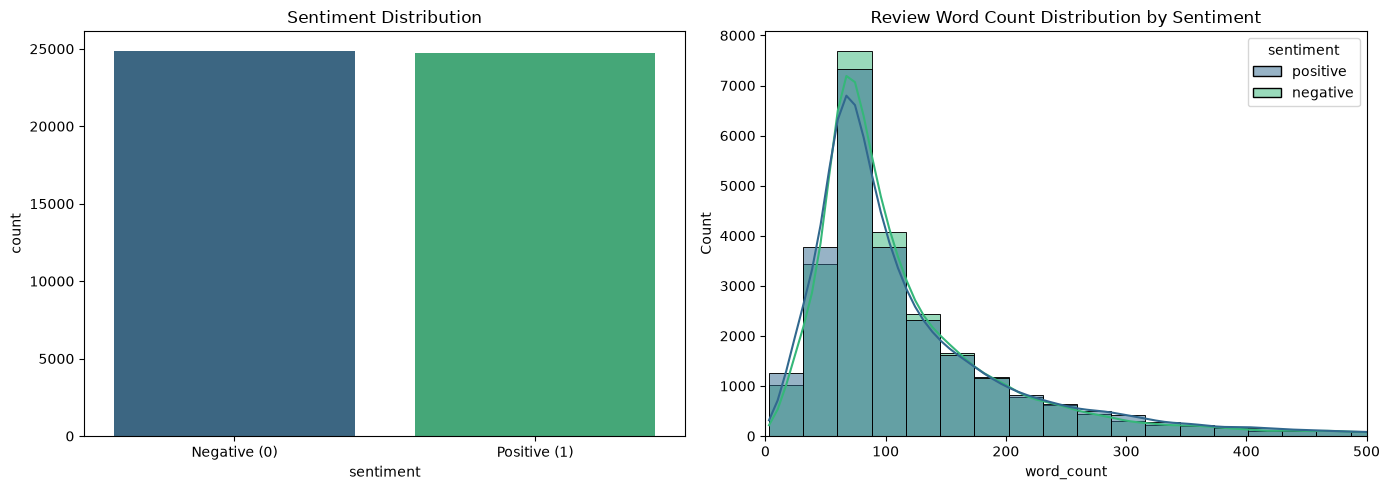


Word Count Statistics:
             count        mean        std  min   25%   50%    75%     max
sentiment                                                                
negative   24698.0  118.383067  86.308006  3.0  65.0  89.0  143.0   836.0
positive   24884.0  121.603641  94.683636  7.0  63.0  89.0  149.0  1426.0


In [4]:
# Calculate word counts
df['word_count'] = df['cleaned_review'].apply(lambda x: len(x.split()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Sentiment Distribution
sns.countplot(data=df, x='sentiment', ax=axes[0], palette='viridis')
axes[0].set_title('Sentiment Distribution')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Negative (0)', 'Positive (1)'])

# Plot 2: Review Length Distribution
sns.histplot(data=df, x='word_count', hue='sentiment', bins=50, kde=True, ax=axes[1], palette='viridis')
axes[1].set_title('Review Word Count Distribution by Sentiment')
axes[1].set_xlim(0, 500) # Capped for readability

plt.tight_layout()
plt.show()

print("\nWord Count Statistics:")
print(df.groupby('sentiment')['word_count'].describe())

In [5]:
# 1. Stratified Split: 80% Train, 10% Val, 10% Test
X_temp, X_test, y_temp, y_test = train_test_split(
    df['cleaned_review'], df['sentiment'], test_size=0.10, random_state=SEED, stratify=df['sentiment']
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.1111, random_state=SEED, stratify=y_temp 
) # 0.1111 of 90% is roughly 10% of total

print(f"Train size: {len(X_train)}, Val size: {len(X_val)}, Test size: {len(X_test)}")

# 2. Build Vocabulary (Only on Training Data)
from collections import Counter

def build_vocab(texts, max_vocab_size=20000):
    word_counts = Counter()
    for text in texts:
        word_counts.update(text.split())
    
    # Most common words, leaving room for PAD and UNK
    most_common = word_counts.most_common(max_vocab_size - 2)
    
    # 0 is reserved for padding, 1 for unknown words
    word2idx = {'<PAD>': 0, '<UNK>': 1}
    for idx, (word, _) in enumerate(most_common, start=2):
        word2idx[word] = idx
        
    return word2idx

vocab = build_vocab(X_train)
print(f"Vocabulary built with {len(vocab)} tokens.")

# 3. Tokenize and Pad Sequences
def text_to_indices(text, word2idx, max_seq_length=200):
    tokens = text.split()
    # Map to index, use 1 (<UNK>) if word is unseen
    indices = [word2idx.get(word, 1) for word in tokens]
    
    # Truncate if too long
    if len(indices) > max_seq_length:
        indices = indices[:max_seq_length]
    # Pad with 0 (<PAD>) if too short
    else:
        indices = indices + [0] * (max_seq_length - len(indices))
        
    return indices

MAX_SEQ_LEN = 200

# Convert all splits
X_train_pad = np.array([text_to_indices(text, vocab, MAX_SEQ_LEN) for text in X_train])
X_val_pad = np.array([text_to_indices(text, vocab, MAX_SEQ_LEN) for text in X_val])
X_test_pad = np.array([text_to_indices(text, vocab, MAX_SEQ_LEN) for text in X_test])

# Convert labels to numpy arrays
y_train_np = np.array(y_train)
y_val_np = np.array(y_val)
y_test_np = np.array(y_test)

Train size: 39665, Val size: 4958, Test size: 4959
Vocabulary built with 20000 tokens.


In [6]:
class IMDBDataset(Dataset):
    def __init__(self, sequences, labels):
        # Convert numpy arrays to appropriate numeric dtype before creating tensors
        # This handles the case where arrays might be of dtype 'object'
        sequences = np.array(sequences, dtype=np.int64)
        
        # Convert string labels to numeric values
        # Map 'positive' to 1 and 'negative' to 0 (or any other string labels)
        if labels.dtype == 'object' or isinstance(labels[0], str):
            # Create a mapping for string labels to numeric values
            label_map = {'positive': 1, 'negative': 0}
            labels = np.array([label_map[label] for label in labels], dtype=np.float32)
        else:
            labels = np.array(labels, dtype=np.float32)
        
        self.sequences = torch.tensor(sequences, dtype=torch.long)
        # Labels must be float for BCEWithLogitsLoss
        self.labels = torch.tensor(labels, dtype=torch.float32) 
        
    def __len__(self):
        return len(self.labels)
    
    def __getitem__(self, idx):
        return self.sequences[idx], self.labels[idx]

BATCH_SIZE = 64

train_dataset = IMDBDataset(X_train_pad, y_train_np)
val_dataset = IMDBDataset(X_val_pad, y_val_np)
test_dataset = IMDBDataset(X_test_pad, y_test_np)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)

In [7]:
class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_layers, bidirectional, dropout_rate):
        super(SentimentLSTM, self).__init__()
        
        # padding_idx=0 ensures the <PAD> token doesn't contribute to gradients
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            bidirectional=bidirectional,
            dropout=dropout_rate if num_layers > 1 else 0,
            batch_first=True
        )
        
        self.dropout = nn.Dropout(dropout_rate)
        
        # If bidirectional, the hidden state size is doubled
        lstm_output_dim = hidden_dim * 2 if bidirectional else hidden_dim
        self.fc = nn.Linear(lstm_output_dim, 1)
        
    def forward(self, x):
        # x shape: (batch_size, seq_length)
        embedded = self.dropout(self.embedding(x))
        # embedded shape: (batch_size, seq_length, embedding_dim)
        
        # output shape: (batch_size, seq_length, hidden_dim * num_directions)
        # hidden shape: (num_layers * num_directions, batch_size, hidden_dim)
        output, (hidden, cell) = self.lstm(embedded)
        
        # We extract the final hidden state to represent the entire sequence
        if self.lstm.bidirectional:
            # Concatenate the final forward and backward hidden states
            hidden_final = torch.cat((hidden[-2,:,:], hidden[-1,:,:]), dim=1)
        else:
            hidden_final = hidden[-1,:,:]
            
        hidden_final = self.dropout(hidden_final)
        logits = self.fc(hidden_final)
        
        return logits.squeeze(-1) # shape: (batch_size,)

# Instantiate Model
MODEL_CONFIG = {
    'vocab_size': len(vocab),
    'embedding_dim': 100,
    'hidden_dim': 256,
    'num_layers': 2,
    'bidirectional': True,
    'dropout_rate': 0.5
}

model = SentimentLSTM(**MODEL_CONFIG).to(device)
print(model)

SentimentLSTM(
  (embedding): Embedding(20000, 100, padding_idx=0)
  (lstm): LSTM(100, 256, num_layers=2, batch_first=True, dropout=0.5, bidirectional=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=512, out_features=1, bias=True)
)


In [8]:
# Check if GPU is available and set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Move model to device - THIS IS CRITICAL for GPU training
model = model.to(device)

optimizer = optim.AdamW(model.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss().to(device)

def calculate_accuracy(logits, labels):
    # Convert logits to probabilities, then round to 0 or 1
    preds = torch.sigmoid(logits).round()
    correct = (preds == labels).float()
    acc = correct.sum() / len(correct)
    return acc

EPOCHS = 10
PATIENCE = 3
best_val_loss = float('inf')
patience_counter = 0

train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(EPOCHS):
    # --- TRAINING ---
    model.train()
    epoch_loss, epoch_acc = 0, 0
    
    # tqdm progress bar
    progress_bar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{EPOCHS} [Train]')
    for sequences, labels in progress_bar:
        # Move data to the same device as model (GPU if available)
        sequences, labels = sequences.to(device), labels.to(device)
        
        optimizer.zero_grad()
        logits = model(sequences)
        loss = criterion(logits, labels)
        acc = calculate_accuracy(logits, labels)
        
        loss.backward()
        # Gradient clipping to prevent exploding gradients
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        
        epoch_loss += loss.item()
        epoch_acc += acc.item()
        progress_bar.set_postfix({'loss': loss.item(), 'acc': acc.item()})
        
    train_losses.append(epoch_loss / len(train_loader))
    train_accs.append(epoch_acc / len(train_loader))
    
    # --- VALIDATION ---
    model.eval()
    val_loss, val_acc = 0, 0
    with torch.no_grad(): # Disable gradients for evaluation to save memory and compute
        for sequences, labels in val_loader:
            # Move validation data to device as well
            sequences, labels = sequences.to(device), labels.to(device)
            logits = model(sequences)
            loss = criterion(logits, labels)
            acc = calculate_accuracy(logits, labels)
            
            val_loss += loss.item()
            val_acc += acc.item()
            
    avg_val_loss = val_loss / len(val_loader)
    avg_val_acc = val_acc / len(val_loader)
    val_losses.append(avg_val_loss)
    val_accs.append(avg_val_acc)
    
    print(f"Val Loss: {avg_val_loss:.4f} | Val Acc: {avg_val_acc:.4f}")
    
    # Early Stopping & Checkpointing
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        patience_counter = 0
        # Save the best model state
        torch.save(model.state_dict(), 'best_lstm_model.pt')
        print(">> Best model saved!")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"Early stopping triggered after {epoch+1} epochs.")
            break

Using device: cuda


Epoch 1/10 [Train]: 100%|██████████| 620/620 [01:16<00:00,  8.07it/s, loss=0.615, acc=0.653]


Val Loss: 0.5402 | Val Acc: 0.7406
>> Best model saved!


Epoch 2/10 [Train]: 100%|██████████| 620/620 [01:14<00:00,  8.31it/s, loss=0.489, acc=0.796]


Val Loss: 0.5128 | Val Acc: 0.7567
>> Best model saved!


Epoch 3/10 [Train]: 100%|██████████| 620/620 [01:17<00:00,  8.04it/s, loss=0.437, acc=0.796]


... (11 outputs left out)

Epoch 9/10 [Train]: 100%|██████████| 620/620 [01:14<00:00,  8.32it/s, loss=0.201, acc=0.939] 


Val Loss: 0.3282 | Val Acc: 0.8853


Epoch 10/10 [Train]: 100%|██████████| 620/620 [01:14<00:00,  8.29it/s, loss=0.304, acc=0.857] 


Val Loss: 0.2961 | Val Acc: 0.8877
Early stopping triggered after 10 epochs.


Classification Report:
              precision    recall  f1-score   support

    Negative       0.87      0.90      0.88      2470
    Positive       0.90      0.87      0.88      2489

    accuracy                           0.88      4959
   macro avg       0.88      0.88      0.88      4959
weighted avg       0.88      0.88      0.88      4959



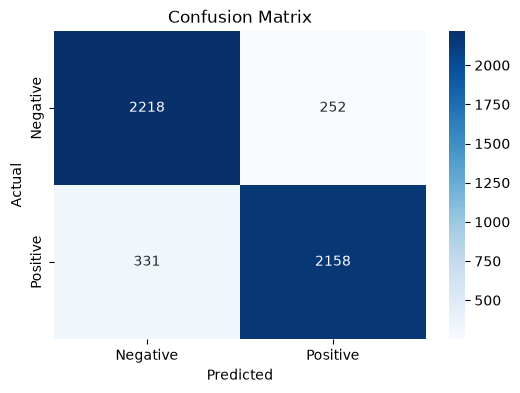

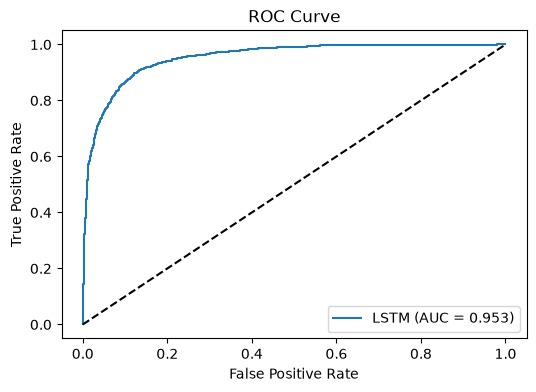

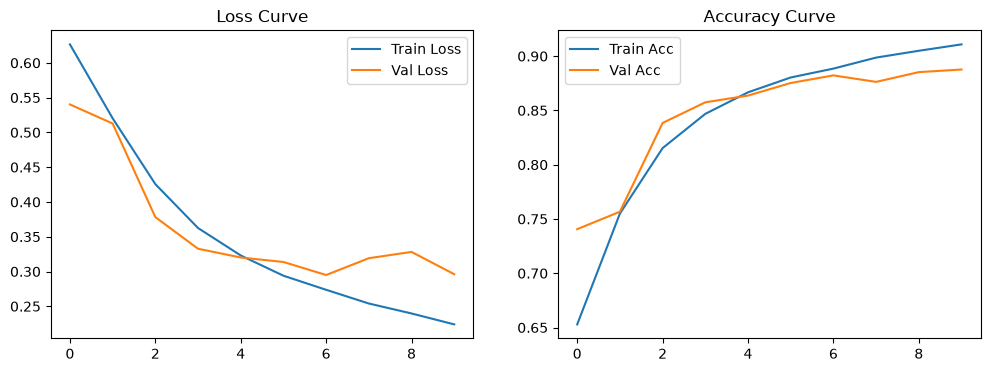

In [9]:
# Load the best weights
model.load_state_dict(torch.load('best_lstm_model.pt'))
model.eval()

test_preds = []
test_labels = []
test_probs = []

with torch.no_grad():
    for sequences, labels in test_loader:
        sequences, labels = sequences.to(device), labels.to(device)
        logits = model(sequences)
        probs = torch.sigmoid(logits)
        preds = probs.round()
        
        test_preds.extend(preds.cpu().numpy())
        test_labels.extend(labels.cpu().numpy())
        test_probs.extend(probs.cpu().numpy())

# 1. Classification Report & Confusion Matrix
print("Classification Report:")
print(classification_report(test_labels, test_preds, target_names=['Negative', 'Positive']))

cm = confusion_matrix(test_labels, test_preds)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# 2. ROC-AUC Curve
auc = roc_auc_score(test_labels, test_probs)
fpr, tpr, _ = roc_curve(test_labels, test_probs)

plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, label=f'LSTM (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# 3. Learning Curves
plt.figure(figsize=(12,4))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.title('Loss Curve')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accs, label='Train Acc')
plt.plot(val_accs, label='Val Acc')
plt.title('Accuracy Curve')
plt.legend()
plt.show()

In [10]:
# Save pipeline artifacts
artifacts = {
    'vocab': vocab,
    'max_seq_len': MAX_SEQ_LEN,
    'model_config': MODEL_CONFIG
}
with open('pipeline_artifacts.json', 'w') as f:
    json.dump(artifacts, f)

print("Model and artifacts saved successfully.")

# --- RELOADING SIMULATION ---
# Assume we are in a new script or session
with open('pipeline_artifacts.json', 'r') as f:
    loaded_artifacts = json.load(f)

loaded_vocab = loaded_artifacts['vocab']
loaded_max_seq_len = loaded_artifacts['max_seq_len']

loaded_model = SentimentLSTM(**loaded_artifacts['model_config'])
loaded_model.load_state_dict(torch.load('best_lstm_model.pt', map_location=device))
loaded_model.to(device)
loaded_model.eval()
print("Pipeline restored.")

Model and artifacts saved successfully.
Pipeline restored.


In [12]:
def predict_sentiment(review_text, model, vocab, max_seq_len, device):
    # 1. Clean using the exact same logic
    cleaned = clean_text(review_text)
    
    # 2. Tokenize and pad
    indices = text_to_indices(cleaned, vocab, max_seq_len)
    
    # 3. Convert to tensor and add batch dimension
    tensor_input = torch.tensor([indices], dtype=torch.long).to(device)
    
    # 4. Predict
    with torch.no_grad():
        logit = model(tensor_input)
        prob = torch.sigmoid(logit).item()
        
    sentiment = "Positive" if prob >= 0.5 else "Negative"
    # Confidence is how far it is from 0.5
    confidence = prob if sentiment == "Positive" else 1 - prob
    
    return sentiment, confidence

# Test Cases
sample_reviews = [
    "The Last Adventure has an interesting premise, but it fails to deliver an engaging experience. The plot is predictable, and many scenes seem unnecessarily long, making the movie feel slow-paced. While the visual effects are impressive, they cannot make up for the weak character development and lack of emotional connection. The dialogue often feels unnatural, and the ending is rushed and unsatisfying. Overall, the movie had potential but falls short due to poor execution.",
    "I hated it. A complete waste of time and money. Terrible acting.",
    "It was okay. Not the best, but certainly not the worst movie I've seen.",
    "Good!", # Very short
    "Loved the first half, but the ending <br/> ruined the entire experience." # Mixed + HTML
]

print("--- Real-time Inference Tests ---\n")
for review in sample_reviews:
    pred, conf = predict_sentiment(review, loaded_model, loaded_vocab, loaded_max_seq_len, device)
    print(f"Review: '{review}'")
    print(f"Prediction: {pred} (Confidence: {conf:.4f})\n")

--- Real-time Inference Tests ---

Review: 'The Last Adventure has an interesting premise, but it fails to deliver an engaging experience. The plot is predictable, and many scenes seem unnecessarily long, making the movie feel slow-paced. While the visual effects are impressive, they cannot make up for the weak character development and lack of emotional connection. The dialogue often feels unnatural, and the ending is rushed and unsatisfying. Overall, the movie had potential but falls short due to poor execution.'
Prediction: Negative (Confidence: 0.9934)

Review: 'I hated it. A complete waste of time and money. Terrible acting.'
Prediction: Negative (Confidence: 0.9957)

Review: 'It was okay. Not the best, but certainly not the worst movie I've seen.'
Prediction: Negative (Confidence: 0.9418)

Review: 'Good!'
Prediction: Positive (Confidence: 0.5604)

Review: 'Loved the first half, but the ending <br/> ruined the entire experience.'
Prediction: Negative (Confidence: 0.8431)

